In [ ]:
# Import all required libraries
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Part 1: Extract S&P 500 tickers from Wikipedia using Pandas
# User-Agent is required to avoid HTTP 403 blocking from Wikipedia
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

tickers = sp500_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]

print('Total tickers extracted:', len(tickers))
sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10)

In [ ]:
#Part2: Load Daily Market Data via yfinance
# Download daily closing prices for all S&P 500 tickers
# Period: 01-01-2021 to 01-01-2025 | Close price (adjusted)
start = '2021-01-01'
end = '2025-01-01'

df = yf.download(tickers, start=start, end=end, auto_adjust=False)['Adj Close']

print('Shape:', df.shape)
df.head()



In [ ]:
# Transpose DataFrame: rows = tickers, columns = dates
df1 = df.T

print('Shape after transpose:', df1.shape)
df1


In [ ]:
# Check original data
print("Original shares:", df.shape[1])
print("Shares after transpose:", df1.shape[0])
print("Missing prices:", df.isna().sum().sum())

In [ ]:
# Check missing data before cleaning

print("Number of shares:", df1.shape[0])
print("Shares with all missing prices:", df1.isna().all(axis=1).sum())
print("Total missing prices:", df1.isna().sum().sum())

In [ ]:
# Check missing data before cleaning

print("Number of shares:", df1.shape[0])

print("Shares with all missing prices:")
print(df1.isna().all(axis=1).sum())

print("Missing prices for each share:")
print(df1.isna().sum(axis=1).sort_values(ascending=False).head(10))

In [ ]:
# Part 3: Identify and Remove Invalid Data
# 1. Drop tickers (rows) that are entirely NaN
# 2. Drop tickers with less than 80% of dates available
# 3. Forward-fill then back-fill remaining gaps
# 4. Drop any remaining fully NaN rows
print('Before cleaning:', df1.shape)

df1 = df1.dropna(how='all')

min_cols = int(0.8 * df1.shape[1])
df1 = df1.dropna(thresh=min_cols)

#ask sir if i should remove this? as long as i explain why I do it
missing_before_fill = df1.isna().sum().sum()
missing_after_ffill = df1.ffill(axis=1).isna().sum().sum()

print("Forward-filled:", missing_before_fill - missing_after_ffill)
print("Backward-filled:", missing_after_ffill)
df1 = df1.ffill(axis=1).bfill(axis=1)

df1 = df1.dropna(how='all')

print('After cleaning:', df1.shape)
print('Rows (tickers) removed:', 503 - df1.shape[0])
df1.head()

In [ ]:
# Check missing values after cleaning
print("Shares remaining:", df1.shape[0])
print("Missing prices remaining:", df1.isna().sum().sum())

In [ ]:
import pandas as pd

def calculate_weekly_returns(df1, shares=None):
    """Calculate weekly returns from df1 (tickers as rows, dates as columns)."""
    prices = df1 if shares is None else df1.loc[shares]

    prices = prices.T.copy()
    prices.index = pd.to_datetime(prices.index)
    prices = prices.sort_index()

    weekly_prices = prices.resample("W-FRI").last()
    return weekly_prices.pct_change(fill_method=None)

In [ ]:
# All shares weekly returns
weekly_returns = calculate_weekly_returns(df1)

In [ ]:
#potentially scale the data or show as %
#mean weekly return
weekly_returns



In [ ]:
#mean weekly returns
mean_weekly_return = weekly_returns.mean()
mean_weekly_return.head()

In [ ]:


def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    """
    weekly_returns: DataFrame with weeks as rows and shares as columns.
    market_returns: Series of benchmark returns indexed by week.
    """
    if min_weeks < 2:
        raise ValueError("min_weeks must be at least 2.")

    results = []

    for share in weekly_returns.columns:
        paired = pd.concat(
            [weekly_returns[share].rename("share"),
             market_returns.rename("market")],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired["market"].var(ddof=1)
        beta = np.nan

        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance

        results.append({
            "Share": share,
            "Beta": beta,
            "Paired_weeks": len(paired)
        })

    return pd.DataFrame(
        results, columns=["Share", "Beta", "Paired_weeks"]
    ).set_index("Share")

In [ ]:
market_prices = yf.download("^GSPC", start=start, end=end, auto_adjust=False)["Adj Close"]
market_weekly_returns = market_prices.resample("W-FRI").last().pct_change(fill_method=None)
market_weekly_returns = pd.DataFrame({"^GSPC": market_weekly_returns.squeeze()})

In [ ]:
# Pass market_weekly_returns as a Series by selecting its column
beta_df = calculate_weekly_beta(
    weekly_returns,
    market_weekly_returns["^GSPC"]
)

beta_df.head()

In [ ]:
print("Cleaned shares:", df1.shape[0])
print("Weekly return shares:", weekly_returns.shape[1])
print("Beta shares:", len(beta_df))

In [ ]:
# Combine into one DataFrame
combined_df = (
    weekly_returns
    .rename_axis(index="Week", columns="Share")
    .reset_index()
    .melt(
        id_vars="Week",
        var_name="Share",
        value_name="Weekly_Return"
    )
    .join(beta_df[["Beta"]], on="Share")
    .sort_values(["Share", "Week"])
    .reset_index(drop=True)
)

combined_df

In [ ]:
# Count null values in each column
print("Null values per column:")
print(combined_df.isna().sum())

# Remove rows with any null values
rows_before = len(combined_df)
combined_df = combined_df.dropna().reset_index(drop=True)

print("Rows removed:", rows_before - len(combined_df))
print("Rows remaining:", len(combined_df))

In [ ]:
# Part 4: Adapted RFM Calculations
# Download daily Close prices and Volume for S&P 500 shares
import yfinance as yf
rfm_data = yf.download(
    tickers,
    start=start,
    end=end,
    auto_adjust=False,
    progress=False
)

close_prices = rfm_data["Close"]
volume_data = rfm_data["Volume"]

print("Close prices:", close_prices.shape)
print("Volume data:", volume_data.shape)

close_prices.head()

In [ ]:
# Part 4: RFM Analysis
# 1.4.1 Calculate Recency

# Download daily trading volume
volume_df = yf.download(
    tickers,
    start=start,
    end=end,
    auto_adjust=False
)['Volume']

volume_df.head()


In [ ]:
# Calculate average volume of previous 20 trading days
average_volume = volume_df.shift(1).rolling(20).mean()

# Identify unusually high trading volume
high_volume = volume_df > (2 * average_volume)

high_volume.head()

In [ ]:

# Calculate Recency for each share
snapshot_date = volume_df.index.max()

recency = {}

for share in volume_df.columns:
    dates = high_volume.index[high_volume[share]]

    if len(dates) > 0:
        last_date = dates.max()
        recency[share] = (snapshot_date - last_date).days
    else:
        recency[share] = np.nan

recency_df = pd.DataFrame(
    recency.items(),
    columns=['Share', 'Recency']
)

recency_df.head(10)


In [ ]:

# Check Recency results
print("Observation date:", snapshot_date)
print("Number of shares:", len(recency_df))
print("Missing Recency values:", recency_df['Recency'].isna().sum())

recency_df.describe()


In [ ]:

# 1.4.2 Calculate Frequency

# Select the last 60 trading days
last_60_days = high_volume.tail(60)

# Count unusually high volume days for each share
frequency = last_60_days.sum()

# Create Frequency DataFrame
frequency_df = pd.DataFrame({
    'Share': frequency.index,
    'Frequency': frequency.values
})

frequency_df.head(10)


In [ ]:

# 1.4.3 Calculate Monetary

# Download daily closing prices
close_df = yf.download(
    tickers,
    start=start,
    end=end,
    auto_adjust=False
)['Close']

close_df.head()


[***********           22%                       ]  112 of 503 completed

In [ ]:

# Select the last 60 trading days
last_60_close = close_df.tail(60)
last_60_volume = volume_df.tail(60)

# Calculate daily traded value
daily_value = last_60_close * last_60_volume

# Calculate total traded value for each share
monetary = daily_value.sum(min_count=60)

# Create Monetary DataFrame
monetary_df = pd.DataFrame({
    'Share': monetary.index,
    'Monetary': monetary.values
})

monetary_df.head(10)


In [ ]:

# Part 4: Combine RFM values

# Combine Recency, Frequency and Monetary
rfm_df = recency_df.merge(
    frequency_df, on='Share'
).merge(
    monetary_df, on='Share'
)

# Check missing values
print("Missing values before cleaning:")
print(rfm_df.isna().sum())

# Remove shares with missing RFM values
rfm_df = rfm_df.dropna().reset_index(drop=True)

print("Shares remaining:", len(rfm_df))

rfm_df.head(10)

In [ ]:
# Align RFM and risk-return to a common valid share set
common_shares = risk_return_df.index.intersection(
    rfm_df['Share']
)

rfm_df = rfm_df[
    rfm_df['Share'].isin(common_shares)
].reset_index(drop=True)

print("RFM shares:", len(rfm_df))
print("Risk-return shares:", len(risk_return_df))

In [31]:

# 1.5 Metric Interpretation

# Summary statistics for RFM
print("RFM Summary Statistics:")
print(rfm_df[['Recency', 'Frequency', 'Monetary']].describe())

# Check correlations between RFM metrics
print("RFM Correlations:")
print(rfm_df[['Recency', 'Frequency', 'Monetary']].corr())


RFM Summary Statistics:
          Recency   Frequency      Monetary
count  498.000000  498.000000  4.980000e+02
mean    20.510040    3.004016  3.961352e+10
std     21.247722    1.327614  1.278859e+11
min      4.000000    0.000000  1.297483e+09
25%     11.000000    2.000000  1.025102e+10
50%     11.000000    3.000000  1.679667e+10
75%     18.000000    4.000000  3.287502e+10
max    222.000000    8.000000  1.847697e+12
RFM Correlations:
            Recency  Frequency  Monetary
Recency    1.000000  -0.340235  0.301770
Frequency -0.340235   1.000000  0.016592
Monetary   0.301770   0.016592  1.000000


In [32]:
#worked RFM example
share = "AAPL"

print("Recency:", recency[share])
print("Frequency:", frequency[share])
print("Monetary:", monetary[share])

Recency: 11
Frequency: 2
Monetary: 623303377706.5842


In [33]:
share = "AAPL"

last_date = high_volume.index[high_volume[share]].max()

print("Last high-volume date:", last_date)
print("Volume on that date:", volume_df.loc[last_date, share])
print("20-day average volume:", average_volume.loc[last_date, share])
print("High-volume threshold:", 2 * average_volume.loc[last_date, share])

Last high-volume date: 2024-12-20 00:00:00
Volume on that date: 147495300
20-day average volume: 45004605.0
High-volume threshold: 90009210.0


In [34]:
print("High-volume days in last 60 sessions:",
      high_volume["AAPL"].tail(60).sum())

High-volume days in last 60 sessions: 2


In [35]:
share = "AAPL"

daily_value = close_df[share].tail(60) * volume_df[share].tail(60)

print("Monetary:", daily_value.sum())

Monetary: 623303377706.5842



# Task 2: Stock Segmentation and Clustering

In [36]:
# Task 2: Stock Segmentation and Clustering
# Part 1: Prepare RFM data for clustering

from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree

# Select RFM features
features = ['Recency', 'Frequency', 'Monetary']

# Create a copy of the RFM data
X = rfm_df.set_index('Share')[features].copy()

# Apply log transformation to Monetary
X['Monetary'] = np.log1p(X['Monetary'])

# Standardise RFM features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Check standardised data
print("Shape:", X_scaled.shape)
print("Mean:", X_scaled.mean(axis=0).round(2))
print("Standard deviation:", X_scaled.std(axis=0).round(2))


Shape: (498, 3)
Mean: [-0. -0.  0.]
Standard deviation: [1. 1. 1.]


In [37]:
# Part 2: Prepare risk and return data for clustering

# Create risk and return feature matrix
risk_return_df = pd.DataFrame({
    'Mean_Weekly_Return': mean_weekly_return,
    'Beta': beta_df['Beta']
})

# Remove missing values
risk_return_df = risk_return_df.dropna()

# Standardise risk and return features
scaler_rr = StandardScaler()
risk_return_scaled = scaler_rr.fit_transform(risk_return_df)

# Check standardised data
print("Shape:", risk_return_scaled.shape)
print("Mean:", risk_return_scaled.mean(axis=0).round(2))
print("Standard deviation:", risk_return_scaled.std(axis=0).round(2))

Shape: (492, 2)
Mean: [-0.  0.]
Standard deviation: [1. 1.]


In [38]:
# Check skewness before transformations
print("RFM Skewness:")
print(rfm_df[['Recency', 'Frequency', 'Monetary']].skew())

print("\nRisk and Return Skewness:")
print(risk_return_df.skew())

RFM Skewness:
Recency       3.610175
Frequency     0.407012
Monetary     11.739518
dtype: float64

Risk and Return Skewness:
Mean_Weekly_Return    0.888632
Beta                  1.198463
dtype: float64


In [39]:
print("Monetary skewness before log transformation:",
      rfm_df['Monetary'].skew())

print("Monetary skewness after log transformation:",
      X['Monetary'].skew())

Monetary skewness before log transformation: 11.739517630960595
Monetary skewness after log transformation: 1.049212190674137


In [40]:
# Check for potential outliers
print("RFM:")
print(rfm_df[['Recency', 'Frequency', 'Monetary']].describe())

print("\nRisk and Return:")
print(risk_return_df.describe())

RFM:
          Recency   Frequency      Monetary
count  498.000000  498.000000  4.980000e+02
mean    20.510040    3.004016  3.961352e+10
std     21.247722    1.327614  1.278859e+11
min      4.000000    0.000000  1.297483e+09
25%     11.000000    2.000000  1.025102e+10
50%     11.000000    3.000000  1.679667e+10
75%     18.000000    4.000000  3.287502e+10
max    222.000000    8.000000  1.847697e+12

Risk and Return:
       Mean_Weekly_Return        Beta
count          492.000000  492.000000
mean             0.002837    0.980436
std              0.002660    0.418519
min             -0.004423    0.056026
25%              0.001141    0.667608
50%              0.002619    0.951188
75%              0.004210    1.182643
max              0.017462    3.778556


In [41]:

# Task 2: Ward Hierarchical Clustering

# Perform hierarchical clustering using Ward's method
hierarchy = linkage(X_scaled, method='ward')

# Check clustering output
print("Hierarchy shape:", hierarchy.shape)

hierarchy[:10]


Hierarchy shape: (497, 4)


array([[2.55000000e+02, 2.61000000e+02, 1.73570536e-04, 2.00000000e+00],
       [1.34000000e+02, 1.61000000e+02, 1.87844163e-04, 2.00000000e+00],
       [3.74000000e+02, 4.75000000e+02, 6.00510118e-04, 2.00000000e+00],
       [7.90000000e+01, 1.99000000e+02, 6.31568555e-04, 2.00000000e+00],
       [1.26000000e+02, 3.25000000e+02, 7.91953059e-04, 2.00000000e+00],
       [1.27000000e+02, 4.38000000e+02, 9.24627315e-04, 2.00000000e+00],
       [1.80000000e+02, 4.43000000e+02, 9.68432615e-04, 2.00000000e+00],
       [3.78000000e+02, 4.40000000e+02, 1.32391121e-03, 2.00000000e+00],
       [3.53000000e+02, 4.14000000e+02, 1.46255241e-03, 2.00000000e+00],
       [2.07000000e+02, 4.63000000e+02, 1.46384838e-03, 2.00000000e+00]])

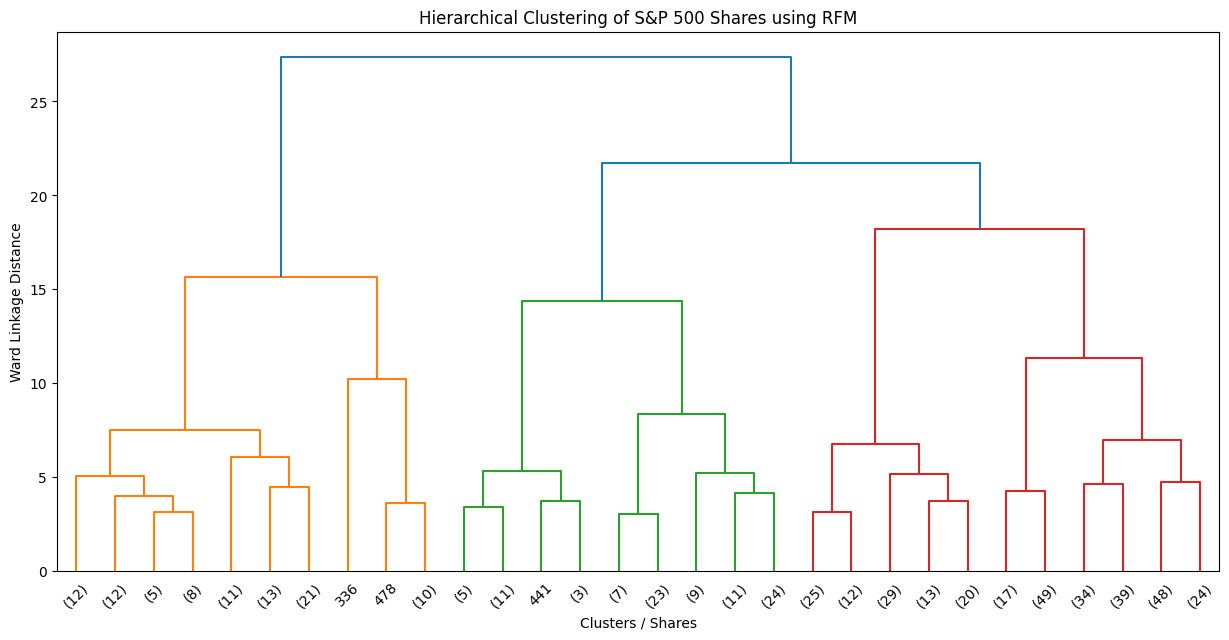

In [42]:

#2.2) Plot Ward hierarchical clustering dendrogram

plt.figure(figsize=(15, 7))

dendrogram(
    hierarchy,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True
)

plt.title('Hierarchical Clustering of S&P 500 Shares using RFM')
plt.xlabel('Clusters / Shares')
plt.ylabel('Ward Linkage Distance')

plt.show()


In [43]:

# Task 2: Assign shares to hierarchical clusters

#selecting clusters
n_clusters = 2

# Assign each share to a cluster
cluster_labels = cut_tree(
    hierarchy,
    n_clusters=n_clusters
).flatten()

# Add cluster labels to RFM DataFrame
rfm_df['Ward_Cluster'] = rfm_df['Share'].map(
    pd.Series(cluster_labels, index=X.index)
)

# Check number of shares in each cluster
print("Shares in each cluster:")
print(rfm_df['Ward_Cluster'].value_counts().sort_index())

rfm_df.head(10)


Shares in each cluster:
Ward_Cluster
0    404
1     94
Name: count, dtype: int64


,Share,Recency,Frequency,Monetary,Ward_Cluster
0,A,11.0,2,1.400180e+10,0
1,AAPL,11.0,2,6.233034e+11,0
2,ABBV,11.0,3,6.837054e+10,0
3,ABNB,11.0,3,3.652850e+10,0
4,ABT,11.0,1,3.523027e+10,0
5,ACGL,11.0,4,1.196213e+10,0
6,ACN,11.0,2,5.199430e+10,0
7,ADBE,18.0,3,1.030403e+11,0
8,ADI,36.0,1,3.849918e+10,1
9,ADM,11.0,3,9.529780e+09,0


In [44]:

# Calculate average RFM values for each cluster

ward_profile = rfm_df.groupby('Ward_Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(2)

print("Ward Cluster Profiles:")
print(ward_profile)


Ward Cluster Profiles:
             Recency Frequency      Monetary      
                mean      mean          mean count
Ward_Cluster                                      
0              12.36      3.22  3.820898e+10   404
1              55.53      2.07  4.565006e+10    94


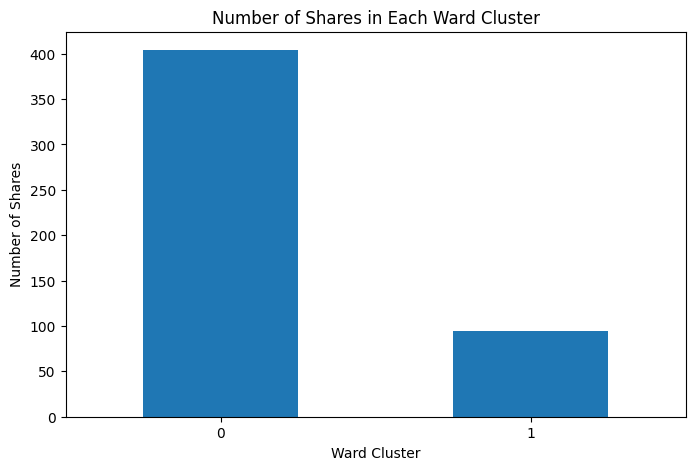

In [45]:

# Plot number of shares in each cluster

plt.figure(figsize=(8, 5))

rfm_df['Ward_Cluster'].value_counts().sort_index().plot(
    kind='bar'
)

plt.title('Number of Shares in Each Ward Cluster')
plt.xlabel('Ward Cluster')
plt.ylabel('Number of Shares')
plt.xticks(rotation=0)

plt.show()


In [46]:
from sklearn.metrics import silhouette_score

# Compare Ward clustering for 2 to 8 clusters
for k in range(2, 9):
    labels = cut_tree(hierarchy, n_clusters=k).flatten()
    score = silhouette_score(X_scaled, labels)

    print("Clusters:", k, "Silhouette score:", round(score, 3))

Clusters: 2 Silhouette score: 0.359
Clusters: 3 Silhouette score: 0.316
Clusters: 4 Silhouette score: 0.288
Clusters: 5 Silhouette score: 0.31
Clusters: 6 Silhouette score: 0.318
Clusters: 7 Silhouette score: 0.306
Clusters: 8 Silhouette score: 0.308


In [47]:
# Check cluster sizes for k = 2
labels_2 = cut_tree(hierarchy, n_clusters=2).flatten()

print(pd.Series(labels_2).value_counts().sort_index())

0    404
1     94
Name: count, dtype: int64


In [48]:
# Calculate RFM profiles for 2 clusters
rfm_df['Ward_Cluster_2'] = rfm_df['Share'].map(
    pd.Series(labels_2, index=X.index)
)

print(rfm_df.groupby('Ward_Cluster_2')[
    ['Recency', 'Frequency', 'Monetary']
].mean().round(2))

                Recency  Frequency      Monetary
Ward_Cluster_2                                  
0                 12.36       3.22  3.820898e+10
1                 55.53       2.07  4.565006e+10


In [49]:
# 2.2 Ward hierarchical clustering for risk and return

hierarchy_rr = linkage(risk_return_scaled, method='ward')

print("Risk and Return hierarchy shape:", hierarchy_rr.shape)

Risk and Return hierarchy shape: (491, 4)


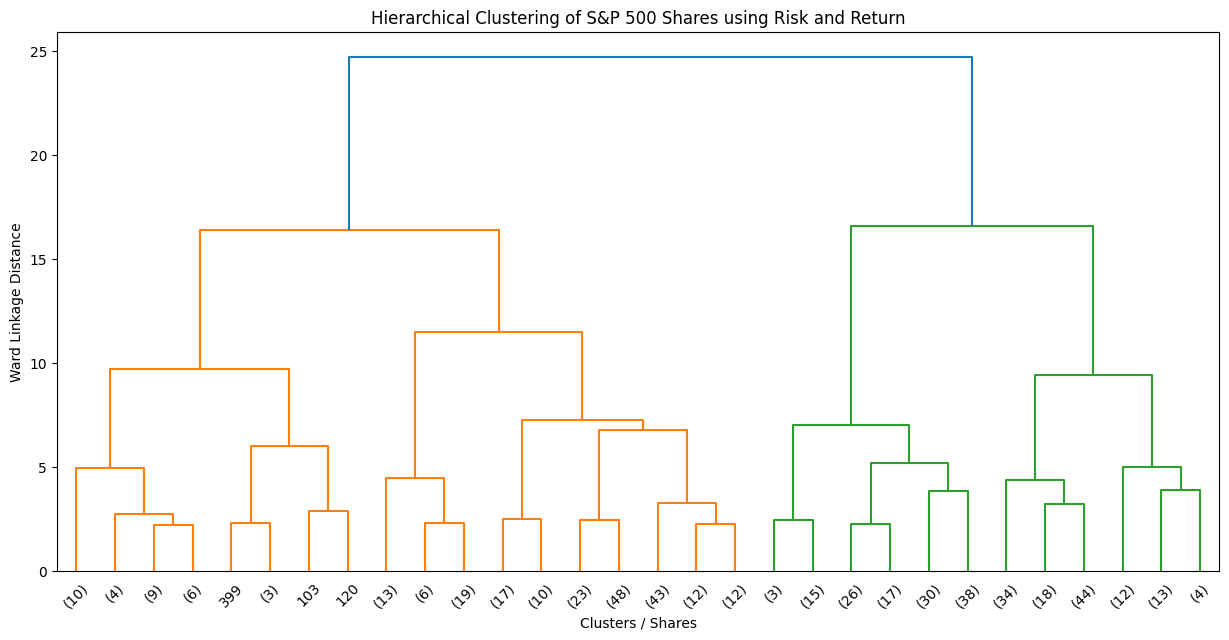

In [50]:
# 2.2 Plot Ward dendrogram for risk and return

plt.figure(figsize=(15, 7))

dendrogram(
    hierarchy_rr,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True
)

plt.title('Hierarchical Clustering of S&P 500 Shares using Risk and Return')
plt.xlabel('Clusters / Shares')
plt.ylabel('Ward Linkage Distance')

plt.show()

In [51]:
# Compare risk and return Ward clustering for 2 to 8 clusters
for k in range(2, 9):
    labels = cut_tree(hierarchy_rr, n_clusters=k).flatten()
    score = silhouette_score(risk_return_scaled, labels)

    print("Clusters:", k, "Silhouette score:", round(score, 3))

Clusters: 2 Silhouette score: 0.292
Clusters: 3 Silhouette score: 0.273
Clusters: 4 Silhouette score: 0.303
Clusters: 5 Silhouette score: 0.306
Clusters: 6 Silhouette score: 0.313
Clusters: 7 Silhouette score: 0.307
Clusters: 8 Silhouette score: 0.292


In [52]:
# Check cluster sizes for k = 5
labels_rr = cut_tree(hierarchy_rr, n_clusters=5).flatten()

print(pd.Series(labels_rr).value_counts().sort_index())

0    125
1    165
2    129
3     38
4     35
Name: count, dtype: int64


In [53]:
#Calculate risk and return profiles for 5 clusters
risk_return_df['Ward_Cluster'] = labels_rr

ward_rr_profile = risk_return_df.groupby('Ward_Cluster').agg({
    'Mean_Weekly_Return': 'mean',
    'Beta': ['mean', 'count']
}).round(4)

print("Risk and Return Ward Cluster Profiles:")
print(ward_rr_profile)

Risk and Return Ward Cluster Profiles:
             Mean_Weekly_Return    Beta      
                           mean    mean count
Ward_Cluster                                 
0                        0.0004  1.1003   125
1                        0.0041  0.9839   165
2                        0.0019  0.5325   129
3                        0.0033  1.5808    38
4                        0.0089  1.5353    35


In [54]:
# Compare risk and return cluster sizes for k = 4, 5 and 6
for k in [4, 5, 6]:
    labels = cut_tree(hierarchy_rr, n_clusters=k).flatten()

    print("Clusters:", k)
    print(pd.Series(labels).value_counts().sort_index())

Clusters: 4
0    125
1    203
2    129
3     35
Name: count, dtype: int64
Clusters: 5
0    125
1    165
2    129
3     38
4     35
Name: count, dtype: int64
Clusters: 6
0    125
1    165
2    129
3     38
4     29
5      6
Name: count, dtype: int64


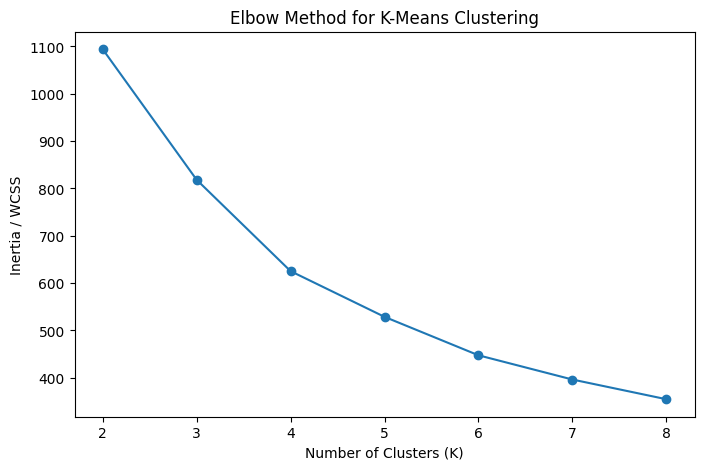

In [55]:
# Task 2.3 K means clustering — (9 marks): K-Means Clustering
# Find the optimal number of clusters using the Elbow Method

from sklearn.cluster import KMeans

inertia = {}

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia[k] = kmeans.inertia_

# Plot Elbow Method
plt.figure(figsize=(8, 5))

plt.plot(
    list(inertia.keys()),
    list(inertia.values()),
    marker='o'
)

plt.title('Elbow Method for K-Means Clustering')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia / WCSS')

plt.show()


In [56]:
# Compare K-Means silhouette scores for 2 to 8 clusters

for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    print("Clusters:", k, "Silhouette score:", round(score, 3))

Clusters: 2 Silhouette score: 0.419
Clusters: 3 Silhouette score: 0.325
Clusters: 4 Silhouette score: 0.34
Clusters: 5 Silhouette score: 0.357
Clusters: 6 Silhouette score: 0.347
Clusters: 7 Silhouette score: 0.349
Clusters: 8 Silhouette score: 0.347


In [57]:
# Compare RFM K-Means cluster sizes for k = 2 to 8

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    print("Clusters:", k)
    print(pd.Series(labels).value_counts().sort_index())

Clusters: 2
0     72
1    426
Name: count, dtype: int64
Clusters: 3
0    276
1     65
2    157
Name: count, dtype: int64
Clusters: 4
0    123
1     98
2    216
3     61
Name: count, dtype: int64
Clusters: 5
0    202
1     11
2     70
3    124
4     91
Name: count, dtype: int64
Clusters: 6
0    107
1     11
2     72
3    120
4     44
5    144
Name: count, dtype: int64
Clusters: 7
0     43
1    144
2    121
3     71
4      1
5    107
6     11
Name: count, dtype: int64
Clusters: 8
0     68
1    108
2     14
3     19
4     63
5    142
6     83
7      1
Name: count, dtype: int64


In [58]:
# Check K-Means cluster sizes for k = 2
model_2 = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_2 = model_2.fit_predict(X_scaled)

print(pd.Series(labels_2).value_counts().sort_index())

0     72
1    426
Name: count, dtype: int64


In [59]:
# Calculate RFM profiles for 2 K-Means clusters
rfm_df['KMeans_Cluster_2'] = rfm_df['Share'].map(
    pd.Series(labels_2, index=X.index)
)

print(rfm_df.groupby('KMeans_Cluster_2')[
    ['Recency', 'Frequency', 'Monetary']
].mean().round(2))

                  Recency  Frequency      Monetary
KMeans_Cluster_2                                  
0                   62.49       1.85  8.060058e+10
1                   13.42       3.20  3.268613e+10


In [60]:
# Ward Cluster Profiles

ward_profile = rfm_df.groupby('Ward_Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(2)

print(ward_profile)


             Recency Frequency      Monetary      
                mean      mean          mean count
Ward_Cluster                                      
0              12.36      3.22  3.820898e+10   404
1              55.53      2.07  4.565006e+10    94


In [61]:
# Task 2: K-Means Clustering

#Create K-Means model with 2 clusters
model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Fit the model using standardised RFM data
model.fit(X_scaled)

# Add K-Means cluster labels to RFM DataFrame
rfm_df['KMeans_Cluster'] = rfm_df['Share'].map(
    pd.Series(model.labels_, index=X.index)
)

# Check number of shares in each cluster
print("K-Means Cluster Sizes:")
print(rfm_df['KMeans_Cluster'].value_counts().sort_index())

rfm_df.head(10)


K-Means Cluster Sizes:
KMeans_Cluster
0     72
1    426
Name: count, dtype: int64


,Share,Recency,Frequency,Monetary,Ward_Cluster,Ward_Cluster_2,KMeans_Cluster_2,KMeans_Cluster
0,A,11.0,2,1.400180e+10,0,0,1,1
1,AAPL,11.0,2,6.233034e+11,0,0,1,1
2,ABBV,11.0,3,6.837054e+10,0,0,1,1
3,ABNB,11.0,3,3.652850e+10,0,0,1,1
4,ABT,11.0,1,3.523027e+10,0,0,1,1
5,ACGL,11.0,4,1.196213e+10,0,0,1,1
6,ACN,11.0,2,5.199430e+10,0,0,1,1
7,ADBE,18.0,3,1.030403e+11,0,0,1,1
8,ADI,36.0,1,3.849918e+10,1,1,0,0
9,ADM,11.0,3,9.529780e+09,0,0,1,1


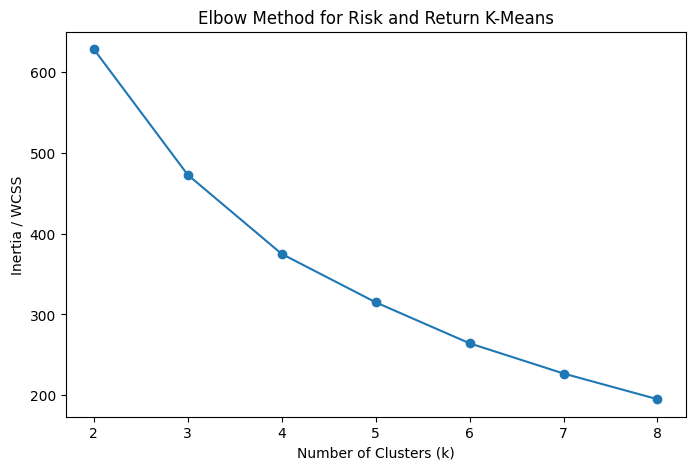

In [62]:
# Risk and return K-Means elbow method
inertia_rr = {}

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(risk_return_scaled)
    inertia_rr[k] = model.inertia_

plt.figure(figsize=(8, 5))
plt.plot(list(inertia_rr.keys()), list(inertia_rr.values()), marker='o')
plt.title('Elbow Method for Risk and Return K-Means')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia / WCSS')
plt.show()

In [63]:
# Task 2.3: K-Means Clustering for Risk and Return

# Create K-Means model with 2 clusters
model_rr = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Fit the model using standardised risk and return data
model_rr.fit(risk_return_scaled)

# Add K-Means cluster labels
risk_return_df['KMeans_Cluster'] = model_rr.labels_

# Check number of shares in each cluster
print("K-Means Cluster Sizes:")
print(risk_return_df['KMeans_Cluster'].value_counts().sort_index())

risk_return_df.head(10)

K-Means Cluster Sizes:
KMeans_Cluster
0    345
1    147
Name: count, dtype: int64


,Mean_Weekly_Return,Beta,Ward_Cluster,KMeans_Cluster
A,0.001081,1.072943,0,0
AAPL,0.003814,1.175478,1,1
ABBV,0.003723,0.425045,2,0
ABNB,0.001397,1.471139,3,1
ABT,0.000888,0.584765,2,0
ACGL,0.005264,0.585791,1,0
ACN,0.002306,1.142431,1,0
ADBE,0.000966,1.549806,0,1
ADI,0.002497,1.132624,1,0
ADM,0.001037,0.547641,2,0


In [64]:
2.3# Compare risk and return K-Means silhouette scores for 2 to 8 clusters

for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(risk_return_scaled)

    score = silhouette_score(risk_return_scaled, labels)

    print("Clusters:", k, "Silhouette score:", round(score, 3))

Clusters: 2 Silhouette score: 0.387
Clusters: 3 Silhouette score: 0.321
Clusters: 4 Silhouette score: 0.324
Clusters: 5 Silhouette score: 0.336
Clusters: 6 Silhouette score: 0.334
Clusters: 7 Silhouette score: 0.336
Clusters: 8 Silhouette score: 0.353


In [65]:
# Compare risk and return K-Means cluster sizes for k = 2 to 8

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(risk_return_scaled)

    print("Clusters:", k)
    print(pd.Series(labels).value_counts().sort_index())

Clusters: 2
0    345
1    147
Name: count, dtype: int64
Clusters: 3
0    165
1    203
2    124
Name: count, dtype: int64
Clusters: 4
0    151
1    130
2     43
3    168
Name: count, dtype: int64
Clusters: 5
0    124
1    169
2     30
3    114
4     55
Name: count, dtype: int64
Clusters: 6
0    109
1     43
2     57
3    158
4      7
5    118
Name: count, dtype: int64
Clusters: 7
0    149
1     71
2     62
3     50
4     72
5      7
6     81
Name: count, dtype: int64
Clusters: 8
0     77
1    137
2     29
3     41
4     77
5      7
6     44
7     80
Name: count, dtype: int64


In [66]:
2.3# K-Means Risk and Return Cluster Profiles

kmeans_rr_profile = risk_return_df.groupby('KMeans_Cluster').agg({
    'Mean_Weekly_Return': 'mean',
    'Beta': ['mean', 'count']
}).round(4)

print("K-Means Risk and Return Cluster Profiles:")
print(kmeans_rr_profile)

K-Means Risk and Return Cluster Profiles:
               Mean_Weekly_Return    Beta      
                             mean    mean count
KMeans_Cluster                                 
0                          0.0018  0.8168   345
1                          0.0053  1.3646   147


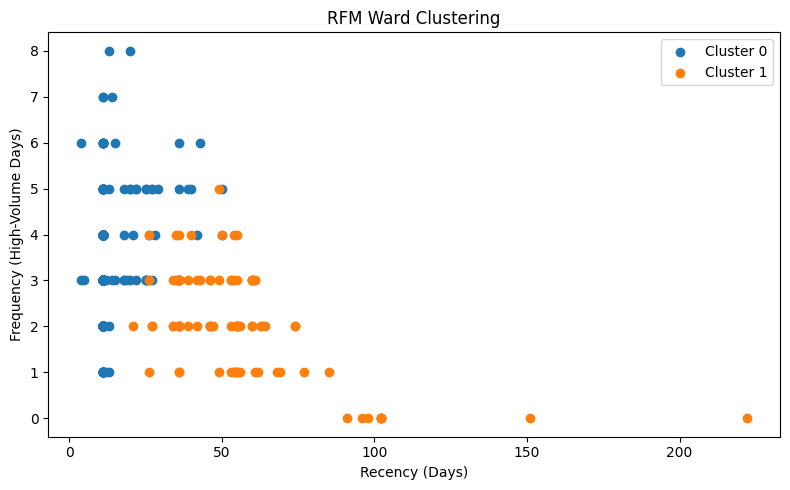

In [67]:
# 2.4 Plot RFM Ward clusters
plt.figure(figsize=(8, 5))

for cluster, group in rfm_df.groupby("Ward_Cluster"):
    plt.scatter(
        group["Recency"], group["Frequency"],
        label=f"Cluster {cluster}"
    )

plt.xlabel("Recency (Days)")
plt.ylabel("Frequency (High-Volume Days)")
plt.title("RFM Ward Clustering")
plt.legend()
plt.tight_layout()
plt.show()

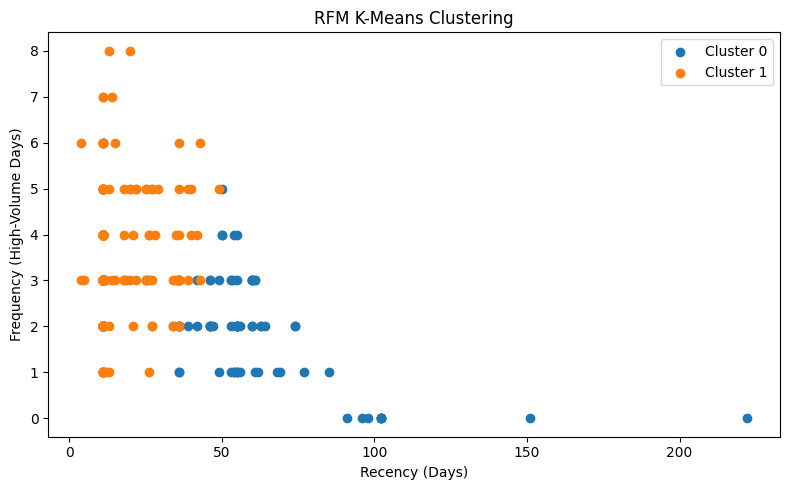

In [68]:
# 2.4 Plot RFM K-Means clusters
plt.figure(figsize=(8, 5))

for cluster, group in rfm_df.groupby("KMeans_Cluster"):
    plt.scatter(
        group["Recency"], group["Frequency"],
        label=f"Cluster {cluster}"
    )

plt.xlabel("Recency (Days)")
plt.ylabel("Frequency (High-Volume Days)")
plt.title("RFM K-Means Clustering")
plt.legend()
plt.tight_layout()
plt.show()

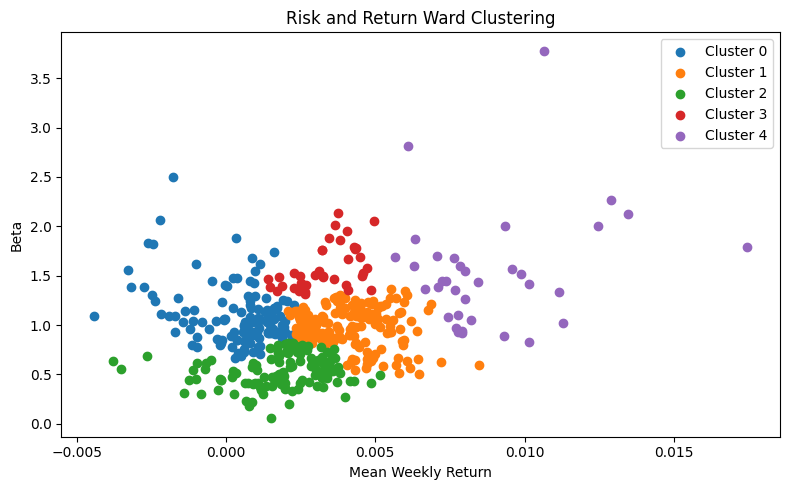

In [69]:
# 2.4 Plot risk and return Ward clusters
plt.figure(figsize=(8, 5))

for cluster, group in risk_return_df.groupby("Ward_Cluster"):
    plt.scatter(
        group["Mean_Weekly_Return"], group["Beta"],
        label=f"Cluster {cluster}"
    )

plt.xlabel("Mean Weekly Return")
plt.ylabel("Beta")
plt.title("Risk and Return Ward Clustering")
plt.legend()
plt.tight_layout()
plt.show()

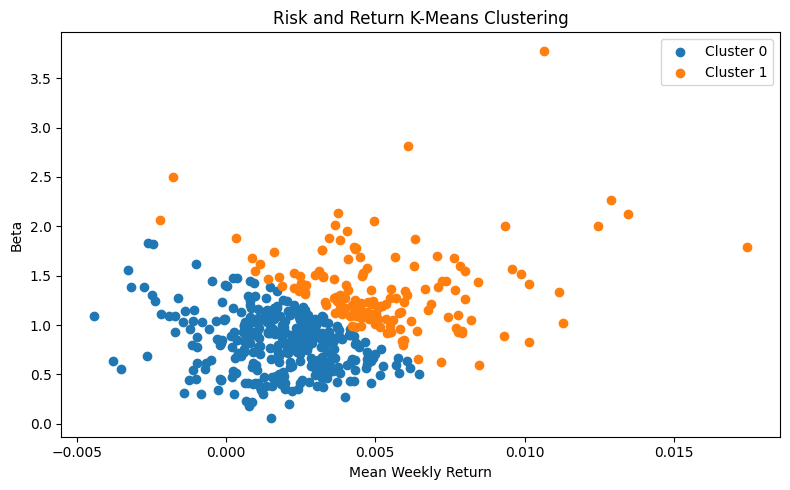

In [70]:
# 2.4 Plot risk and return K-Means clusters
plt.figure(figsize=(8, 5))

for cluster, group in risk_return_df.groupby("KMeans_Cluster"):
    plt.scatter(
        group["Mean_Weekly_Return"], group["Beta"],
        label=f"Cluster {cluster}"
    )

plt.xlabel("Mean Weekly Return")
plt.ylabel("Beta")
plt.title("Risk and Return K-Means Clustering")
plt.legend()
plt.tight_layout()
plt.show()

In [71]:
# 2.4 Compare Ward and K-Means for risk and return

comparison_rr = pd.crosstab(
    risk_return_df['Ward_Cluster'],
    risk_return_df['KMeans_Cluster']
)

print("Ward vs K-Means Risk and Return:")
print(comparison_rr)

Ward vs K-Means Risk and Return:
KMeans_Cluster    0   1
Ward_Cluster           
0               118   7
1                96  69
2               129   0
3                 2  36
4                 0  35


In [72]:
# 2.5.1 Correlation analysis

features = rfm_df[["Recency", "Frequency", "Monetary"]].dropna().copy()

features["LogMonetary"] = np.log1p(features["Monetary"])

print("Correlations among the clustering inputs:")
print(
    features[["Recency", "Frequency", "LogMonetary"]]
    .corr()
    .round(2)
)

Correlations among the clustering inputs:
             Recency  Frequency  LogMonetary
Recency         1.00      -0.34         0.16
Frequency      -0.34       1.00         0.02
LogMonetary     0.16       0.02         1.00


In [73]:
# 2.5.2 Ward clustering without Monetary

X_reduced = features[["Recency", "Frequency"]]

X_reduced_scaled = StandardScaler().fit_transform(X_reduced)

hierarchy_reduced = linkage(X_reduced_scaled, method="ward")

labels_reduced = cut_tree(hierarchy_reduced, n_clusters=2).ravel() + 1

print(pd.Series(labels_reduced).value_counts().sort_index())

1    405
2     93
Name: count, dtype: int64


In [74]:
# 2.5.2 Compare Ward clusters with and without Monetary

from sklearn.metrics import adjusted_rand_score

ari_score = adjusted_rand_score(
    rfm_df['Ward_Cluster'],
    labels_reduced
)

print("Adjusted Rand Index:", round(ari_score, 3))

Adjusted Rand Index: 0.953


In [75]:
# 2.5.2 Compare Monetary profiles

rfm_df['Ward_Reduced'] = labels_reduced

print("Original Ward clusters:")
print(rfm_df.groupby('Ward_Cluster').agg({
    'Monetary': ['mean', 'count']
}).round(2))

print("Ward clusters without Monetary:")
print(rfm_df.groupby('Ward_Reduced').agg({
    'Monetary': ['mean', 'count']
}).round(2))

Original Ward clusters:
                  Monetary      
                      mean count
Ward_Cluster                    
0             3.820898e+10   404
1             4.565006e+10    94
Ward clusters without Monetary:
                  Monetary      
                      mean count
Ward_Reduced                    
1             3.768854e+10   405
2             4.799647e+10    93
